# H4a Polaryzacja afektywna (WPA)

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.config import (CYCLES, PHASE_COLORS, PHASE_ORDER, POLITICAL_SUBREDDITS, PROCESSED_DIR, RESULTS_DIR, SUBREDDIT_STYLES,
                        WPA_MIN_PER_GROUP)

H4A_DIR = PROCESSED_DIR / "h4a"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CELLS = ["subreddit", "cycle", "phase"]

## 2. Połączenie wzmianek z wynikami modelu

In [2]:
mentions = pd.read_parquet(H4A_DIR / "mentions.parquet", columns=["id", "subreddit", "cycle", "phase", "target", "term_type"])
stance = pd.concat(pd.read_parquet(path) for path in sorted(H4A_DIR.glob("stance_*.parquet")))
data = mentions.merge(stance, on="id")
print(len(mentions), len(data))

95312 95312


## 3. WPA = odsetek krytyki obozu przeciwnego − własnego

In [3]:
variants = {"wpa": "critical", "wpa_3class": "critical_3"}
scopes = {"all": data, "party": data[data["term_type"] == "party"], "politician": data[data["term_type"] == "politician"]}
tables = []
for scope, subset in scopes.items():
    for variant, column in variants.items():
        rate = subset.pivot_table(index=CELLS, columns="target", values=column, aggfunc="mean").reindex(columns=["out", "own"])
        count = subset.pivot_table(index=CELLS, columns="target", values=column, aggfunc="size").reindex(columns=["out", "own"])
        table = pd.DataFrame({"n_out": count["out"], "n_own": count["own"], "wpa": rate["out"] - rate["own"]})
        table.loc[(table["n_out"] < WPA_MIN_PER_GROUP) | (table["n_own"] < WPA_MIN_PER_GROUP), "wpa"] = float("nan")
        tables.append(table.assign(scope=scope, variant=variant).reset_index())
wpa = pd.concat(tables, ignore_index=True)
wpa.to_csv(RESULTS_DIR / "h4a_wpa.csv", index=False)
main = wpa[(wpa["scope"] == "all") & (wpa["variant"] == "wpa")]
wpa_table = main.pivot_table(index=["subreddit", "phase"], columns="cycle", values="wpa")
wpa_table.round(3)

cycle                        2012   2016   2020   2024
subreddit    phase                                    
Conservative bazowa         0.014  0.143  0.209  0.101
             powyborcza     0.077  0.072  0.112  0.151
             przedwyborcza  0.005  0.135  0.183  0.122
             przejsciowa    0.037  0.140  0.056  0.216
             szczytowa      0.065  0.091  0.156  0.211
Liberal      bazowa           NaN  0.118  0.198  0.267
             powyborcza     0.213  0.199  0.138  0.224
             przedwyborcza  0.160  0.114  0.196  0.260
             przejsciowa    0.175  0.106  0.247  0.137
             szczytowa      0.222  0.170  0.289  0.309
Republican   bazowa        -0.219  0.066  0.235  0.091
             powyborcza    -0.021 -0.003  0.145  0.219
             przedwyborcza -0.035  0.020  0.262  0.182
             przejsciowa   -0.040  0.061  0.144  0.279
             szczytowa      0.013 -0.079  0.337  0.250
democrats    bazowa           NaN  0.214  0.215  0.279
             powyborcza     0.251  0.107  0.225  0.120
             przedwyborcza  0.233  0.139  0.290  0.291
             przejsciowa    0.353  0.173  0.275  0.199
             szczytowa      0.295  0.225  0.316  0.428

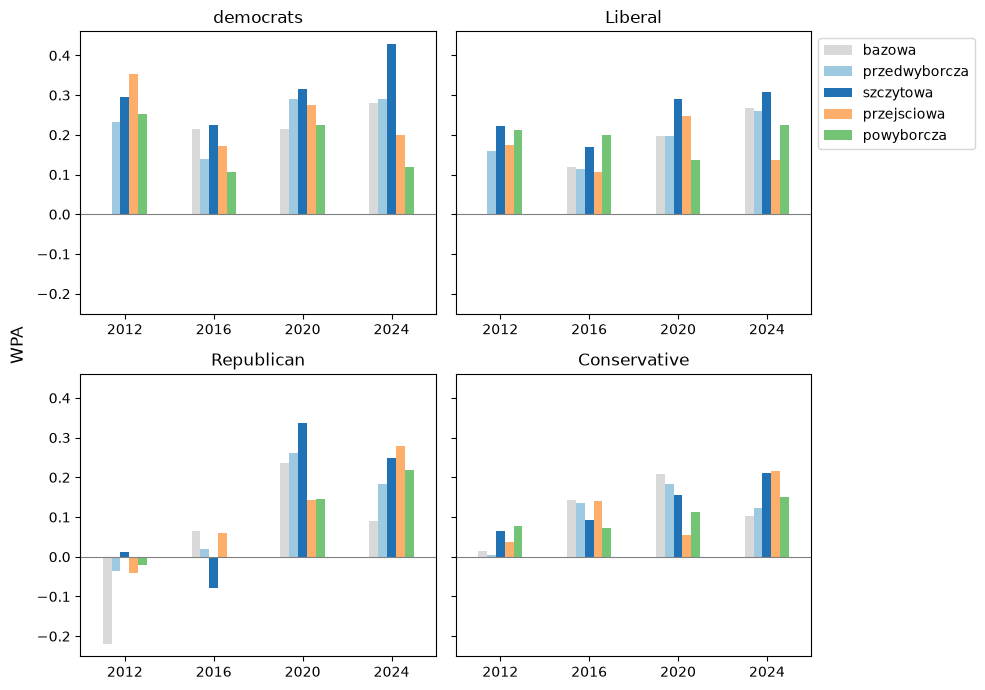

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for ax, subreddit in zip(axes.ravel(), POLITICAL_SUBREDDITS):
    (wpa_table.loc[subreddit].reindex(index=PHASE_ORDER, columns=CYCLES).T
     .plot.bar(ax=ax, rot=0, legend=False, color=[PHASE_COLORS[phase] for phase in PHASE_ORDER]))
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(subreddit)
    ax.set_xlabel("")
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel("WPA")
plt.tight_layout()
plt.show()

In [5]:
print("komórki bez WPA (za mało komentarzy w koszyku):")
main[main["wpa"].isna()][CELLS + ["n_out", "n_own"]]

komórki bez WPA (za mało komentarzy w koszyku):


,subreddit,cycle,phase,n_out,n_own
20,Liberal,2012,bazowa,21,38
60,democrats,2012,bazowa,48,38


## 4. Porównanie: 2020 + 2024 vs 2012 + 2016

In [6]:
main = main.assign(period=main["cycle"].map(lambda cycle: "2020+2024" if cycle >= 2020 else "2012+2016"))
comparison = main[main["phase"].isin(["szczytowa", "przejsciowa"])].groupby(["phase", "period"])["wpa"].agg(mean="mean", n_cells="count")
comparison.to_csv(RESULTS_DIR / "h4a_period_comparison.csv")
comparison.round(3)

mean  n_cells
phase       period                   
przejsciowa 2012+2016  0.125        8
            2020+2024  0.194        8
szczytowa   2012+2016  0.125        8
            2020+2024  0.287        8

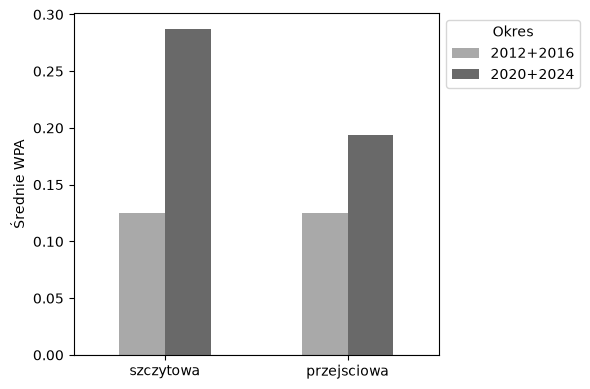

In [7]:
ax = comparison["mean"].unstack("period").loc[["szczytowa", "przejsciowa"]].plot.bar(figsize=(6, 4), rot=0, color=["darkgray", "dimgray"])
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("")
ax.set_ylabel("Średnie WPA")
ax.legend(title="Okres", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 5. Analiza wrażliwości: typ terminu i wariant z trzech klas

In [8]:
sensitivity = wpa[wpa["phase"].isin(["szczytowa", "przejsciowa"])].pivot_table(index=["scope", "variant", "phase"], columns="cycle", values="wpa", aggfunc="mean")
sensitivity.round(3)

cycle                               2012   2016   2020   2024
scope      variant    phase                                  
all        wpa        przejsciowa  0.131  0.120  0.180  0.208
                      szczytowa    0.149  0.102  0.275  0.299
           wpa_3class przejsciowa  0.150  0.129  0.180  0.211
                      szczytowa    0.148  0.102  0.294  0.297
party      wpa        przejsciowa  0.129  0.132  0.150  0.183
                      szczytowa    0.151  0.104  0.202  0.228
           wpa_3class przejsciowa  0.158  0.143  0.161  0.201
                      szczytowa    0.153  0.110  0.229  0.229
politician wpa        przejsciowa -0.032  0.126  0.198  0.223
                      szczytowa    0.143  0.104  0.310  0.321
           wpa_3class przejsciowa  0.019  0.134  0.189  0.217
                      szczytowa    0.140  0.102  0.320  0.315

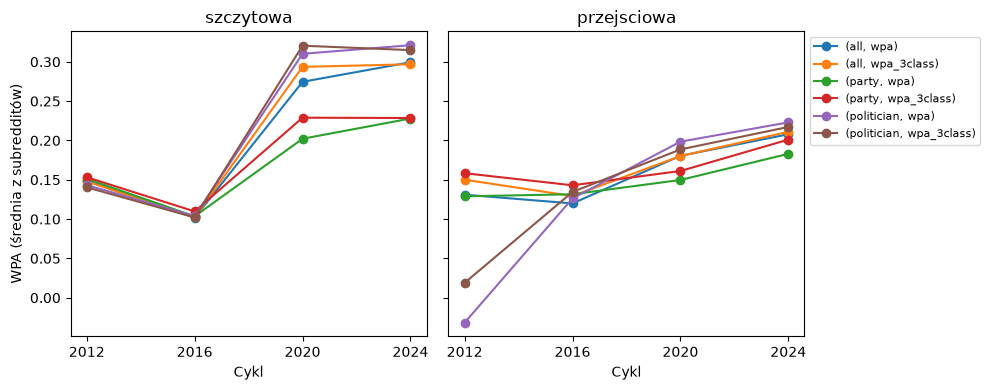

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, phase in zip(axes, ["szczytowa", "przejsciowa"]):
    sensitivity.xs(phase, level="phase").T.reindex(CYCLES).plot(ax=ax, marker="o", legend=False)
    ax.set_title(phase)
    ax.set_xticks(CYCLES)
    ax.set_xlabel("Cykl")
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
axes[0].set_ylabel("WPA (średnia z subredditów)")
plt.tight_layout()
plt.show()

## 6. Wykres roboczy

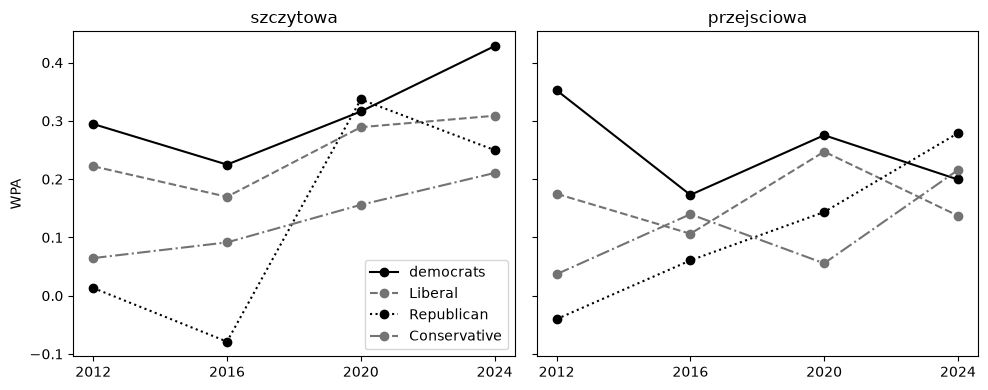

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, phase in zip(axes, ["szczytowa", "przejsciowa"]):
    for subreddit in POLITICAL_SUBREDDITS:
        rows = main[(main["subreddit"] == subreddit) & (main["phase"] == phase)].set_index("cycle").reindex(CYCLES)
        color, linestyle = SUBREDDIT_STYLES[subreddit]
        ax.plot(CYCLES, rows["wpa"], color=color, linestyle=linestyle, marker="o", label=subreddit)
    ax.set_title(phase)
    ax.set_xticks(CYCLES)
axes[0].legend()
axes[0].set_ylabel("WPA")
plt.tight_layout()
plt.show()